## Création fichier étalonnage des thermocouples

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
import pandas as pd
import datetime
import os
import scipy as sc
import json

# Importation des données

In [36]:
def h5_to_df(data : h5py.h5) : # Chargement des données h5 dans un DataFrames
    dict_data = {}
    for (mesure,voie,start,stop) in data :
        if mesure == "Température" :
            if stop == -1 :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][start:]
            elif start == 0 :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][:stop]
            else :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][start:stop]
            dict_data["CH"+str(voie)] = [TC[i][0] for i in range(len(TC))]
            continue
        elif mesure == "Pression" :
            if stop == -1 :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:]
            elif start == 0 :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][:stop]
            else :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:stop]
            dict_data[mesure] = [(P[i][0]-0.0253)/4.9731 for i in range(len(P))]
            continue
        elif mesure == "Voltage" :
            if stop == -1 :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:]
            elif start == 0 :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][:stop]
            else :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:stop]
            dict_data[mesure] = [U[i][0] for i in range(len(U))]
            continue
        elif mesure == "time" :
            if stop == -1 :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][start:]
            elif start == 0 :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][:stop]
            else :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][start:stop]
            dict_data["Date"] = [datetime.datetime.fromtimestamp(i) for i in t]
            dict_data["Temps"] = list(t-t[0])
            continue
        
    df = pd.DataFrame(dict_data)
        
    return  df

In [37]:
path = r"C:\Users\yseyve\Documents\scripts\LinearCalibrationMethod\examples_calibration\Scan_20260113_17_57_54.h5"
plateau = [10,30,50,70,90,110,130,150] ## Température d'étalonnage

## Importation données brut
File = h5py.File(path,'r')

## Choix des données traitées
start = 0
stop = -1

## Création dictionnaire des variables à récupérer
data_in = [("time","02",start,stop),("Voltage","00",start,stop),\
           ("Voltage","01",start,stop),("Pression","02",start,stop),\
           ("Température","01",start,stop),("Température","02",start,stop),\
           ("Température","03",start,stop),("Température","04",start,stop),\
           ("Température","05",start,stop),\
           ("Température","07",start,stop),("Température","08",start,stop),\
           ("Température","09",start,stop),("Température","10",start,stop)]

df_data= h5_to_df(data_in)


## Préparation données de l'étalonnage

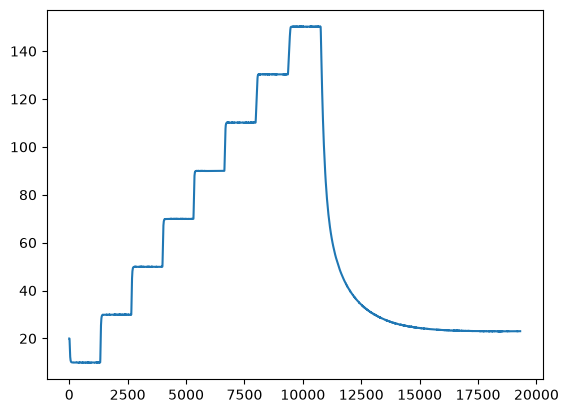

In [38]:
plt.plot(df_data["CH01"])

In [39]:
def delete_usless_data(data) :

    # Find minimum and maximum value and save there index
    ind_min = list(data).index(np.min(data))
    ind_max = list(data).index(np.max(data))

    # Cut data end keep only value between maximum and minumum
    data_use = data[ind_min:ind_max]

    data_use.reset_index(inplace = True,drop=True)

    return data_use

def copy_and_delete_from_series(series: pd.Series, start_index: int, end_index: int) -> pd.Series:
    """
    Copie et supprime une plage d'index d'une Series pandas.

    Args:
        series: La Series pandas d'origine.
        start_index: Index de début (inclus).
        end_index: Index de fin (inclus).

    Returns:
        Une nouvelle Series contenant les éléments copiés.
    """
    # Copie la plage spécifiée
    copied_series = series.loc[start_index:end_index].copy()

    # Supprime la plage de la série originale
    series.drop(index=series.index[start_index:end_index+1], inplace=True)

    return copied_series

def tray_separation(data,plateau) :
    """
    Separate value of calibration in differente tray

    Args:
        data : data to separate
        plateau : tray that fix during calibration
    Returns:
        Cut data in differente tray store in dictionnary
    """
    # Calculate mean value between tray
    cut_values = [(plateau[i]+plateau[df_data.index[df_data.index[df_data.index[df_data.index[df_data.index[i+1]]]]]])/2 for i in range(len(plateau)-1)]

    # copy data
    data_copy = data.copy()

    # creat dictionnary to store data
    df = pd.DataFrame(index=plateau,columns=["Data"])
    for i in range(len(cut_values)) :
        # Calculate absolute difference to determine closest value of cut_values
        abs_values = np.abs(data_copy-cut_values[i])
        # Find index of this value
        ind_cut = list(abs_values).index(np.min(abs_values))
        # Add in dictionnary all values between 0 and ind_cut index and delete them of data_copy
        df.at[plateau[i], "Data"] = copy_and_delete_from_series(data_copy,0,ind_cut)
        # Reset index of data_copy for index function
        data_copy.reset_index(inplace = True,drop=True)
        
    # Add all values in last tray
    df.at[plateau[i+1], "Data"] = data_copy

    return df

def find_index_std(df,step_std,prec) :
    """
    Determine the minimum and maximum indices for which the data points have a constant standard deviation.

    Args:
        dict_value : Dictionnary with values
        step_std : Number of parition data to calculate standard deviation
        prec : Precision that 2 standard deviation must reached to satisfied constant condition
    Returns:
        A dictionary containing only stable data sets
    """
    for j in df.index :
        N = len(df.loc[j,"Data"])
        for i in range(0,step_std) :
            if i == 0 :
                e_c = [np.std(df.loc[j,"Data"][int(0+i*(1/step_std)*int(N/2)):int(N-i*(1/step_std)*int(N/2))])]
            else :
                e_c.append(np.std(df.loc[j,"Data"][int(0+i*(1/step_std)*int(N/2)):int(N-i*(1/step_std)*int(N/2))]))
                if np.abs(e_c[-1]-e_c[-2]) < prec :
                    opt_ind_down = int(0+i*(1/step_std)*int(N/2))
                    opt_ind_up = int(N-i*(1/step_std)*int(N/2))
                    df.at[j,"Data"] = df.at[j,"Data"][opt_ind_down:opt_ind_up]
                    df.at[j,"Data"].reset_index(inplace = True,drop=True)
                    df.at[j,"N"] = int(len(df.at[j,"Data"]))
                    break
                else : 
                    continue

    return df

In [40]:
def Brown_Forsythe_Test(data) :

    F, p = sc.stats.levene(data, center = "median")

    return F, p

In [41]:
## Calcul par moindre carré
def sensor_etalonnage(df_data,plateau) :
    """
    Calcul de droite d'étalonnage et de l'incertitude lors de son utilisation par la méthode point moyen avec variances variables.

    Args:
        data_sensor (dataframe) : Mesure des température de l'étalonnage.
        plateau (liste) : Valeur des plateaux défini pour l'étalonnage.

    """

    ## Calcul des coefficients a et b
    x_bar = np.sum(df_data["g"]*df_data.index)/np.sum(df_data["g"])
    y_bar = np.sum(df_data["g"]*df_data["Mean"])/np.sum(df_data["g"])

    ## Calcul de du coefficient de pente b et a (ordonné à l'origine)
    b = np.sum(df_data["g"]*(df_data.index-x_bar)*(df_data["Mean"]-y_bar))/sum(df_data["g"]*(df_data.index-x_bar)**2)
    a = y_bar-b*x_bar

    Q = np.sum(df_data["g"]*(df_data["Mean"]-a-b*df_data.index)**2)
    K = Q/(np.sum(df_data["N"])-2)
    var_b = K/np.sum(df_data["g"]*(df_data.index-x_bar)**2)
    var_y_bar = K/np.sum(df_data["N"]*df_data["g"])
    var_a = var_y_bar+x_bar**2*var_b
    cov_var_ab = -x_bar*var_b**2
    var_sy_mean = K/np.sum(df_data["g"])

    ## Checking linear regression

    chi2 = Q/K
    chi2_pearson = sc.stats.chi2.isf(0.01,np.sum(df_data["N"])-2) # -2 car 2 paramètres (a,b) dans la corrélation linéaire

    # F,p = Brown_Forsythe_Test(df_data["Data"])

    if chi2 < chi2_pearson :
        print("Linearity is validate by chi2 test")
    else :
        print("Becareful, linearity is not validate by chi2 test. You must check error on reference value x or suppose correlation is not linear.")

    return a,b,var_a,var_b,var_sy_mean, x_bar,K,df_data


In [42]:
def test_Snedecor(df_data : pd.DataFrame, a : float , b : float) :

    ## Checking linear regression

    Q = np.sum(df_data["g"][0:3] * [np.sum((df_data.at[i,"Data"] - a - b*i)**2) for i in df_data.index[0:3]])

    Q_R = np.sum(df_data["g"][0:3] * [np.sum((df_data.at[i,"Data"] - df_data.at[i,"Mean"])**2) for i in df_data.index[0:3]])

    p = len(df_data.index[0:3])
    N = np.sum(df_data["N"][0:3])

    K_R = Q_R/(N-p)
    K_1 = (Q-Q_R)/(p-2)

    F = K_1/K_R

    F_snec = sc.special.fdtri(p-2,N-p,0.95)

    if F < F_snec :
        print("Linear regression is validate")
    else :
        print("Linear regression is unvalidate")
        print("Error on reference temperature or relation between x and y is not linear")

    return

Linearity is validate by chi2 test
 CH01 : a = -0.19614409795036636 et b = 1.002880047448856
Linearity is validate by chi2 test
 CH02 : a = -0.49571726989401554 et b = 1.0034589389491446
Linearity is validate by chi2 test
 CH03 : a = -0.5738479342588647 et b = 1.006383044528459
Linearity is validate by chi2 test
 CH04 : a = -0.44805889235796315 et b = 1.0027703237728123
Linearity is validate by chi2 test
 CH05 : a = -0.08970442346081597 et b = 0.9986409462638056
Linearity is validate by chi2 test
 CH07 : a = -0.1491292648601643 et b = 1.0001693741678501
Linearity is validate by chi2 test
 CH08 : a = -0.11016205404808943 et b = 0.9985560601021223
Linearity is validate by chi2 test
 CH09 : a = -0.19026414551468918 et b = 1.0028006969050038
Linearity is validate by chi2 test
 CH10 : a = -0.15718668647588174 et b = 1.0014998788482405


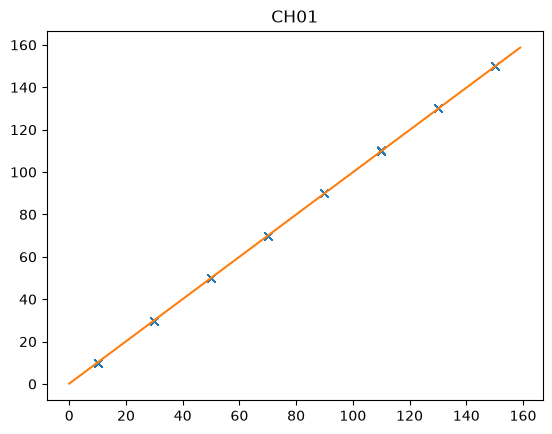

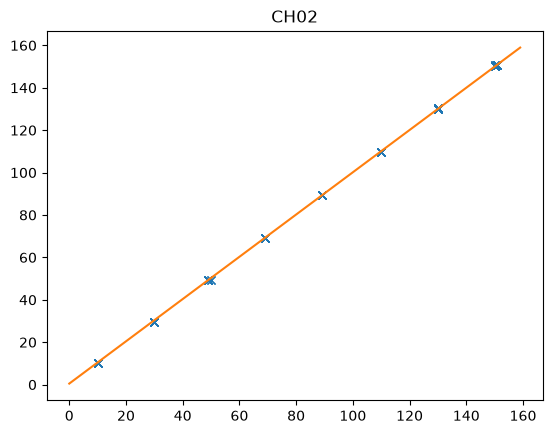

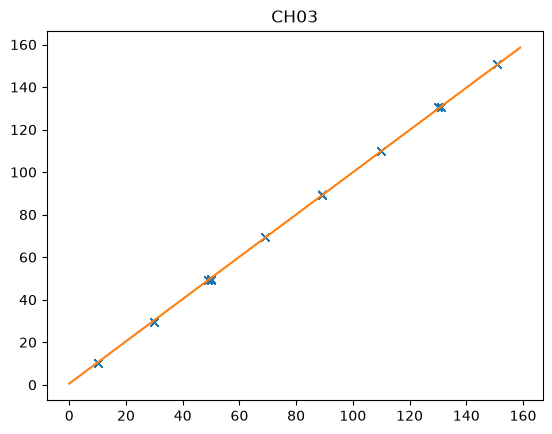

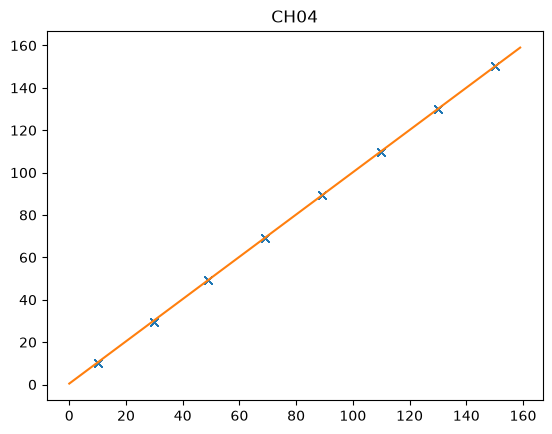

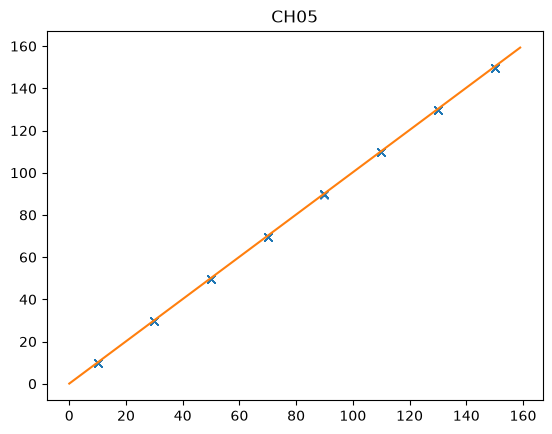

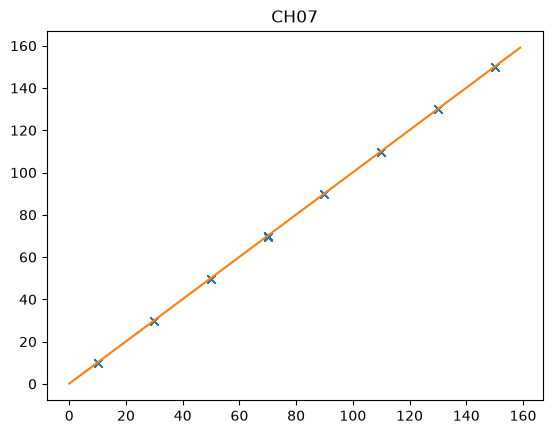

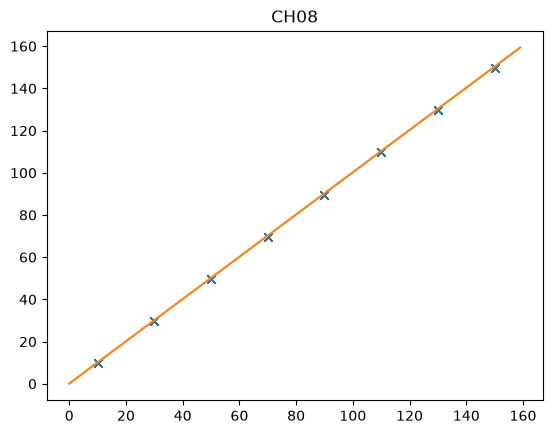

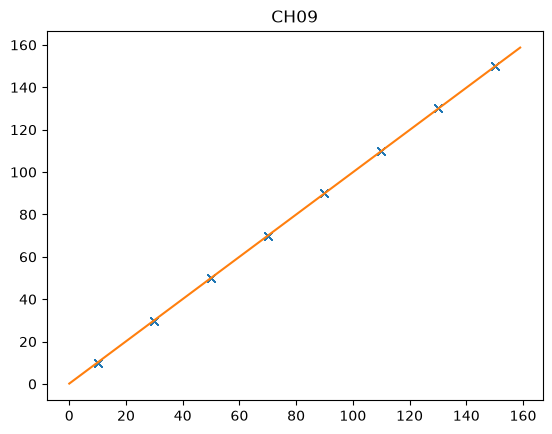

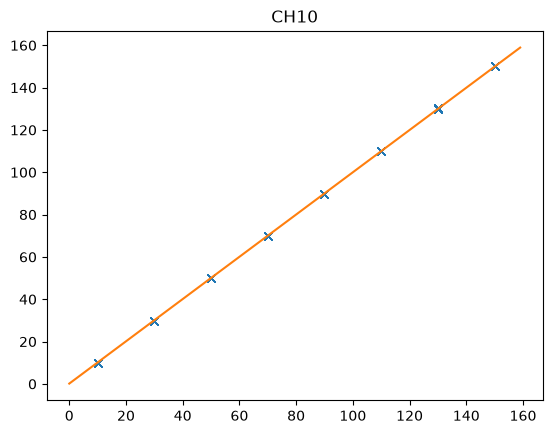

In [43]:

def calc_spy2_mc(data, prec, plateau, std_x : float) : 

    dict_std = {}

    ## Calcul des poids g
    for i in data.index :
        data.at[i,"Std"] = np.std(data.at[i,"Data"])
        data.at[i,"Mean"] = np.mean(data.at[i,"Data"])
    
    std_std = np.std(data["Std"])

    if std_std < prec :
        data["g"] = [1]*len(data.index)
    else :
        b0, a0 = np.polyfit(plateau, data["Mean"],1)
        for i in data.index :
            data.at[i,"g"] = 1/((data.at[i,"Std"]**2/data.at[i,"N"])+(b0**2*std_x**2))
    
    ## Moindre caré

    a,b,var_a,var_b,var_sy_mean, x_bar,K,df_data = sensor_etalonnage(data,plateau)

    return a,b,var_a,var_b,var_sy_mean,x_bar,K,df_data
 

dict_data = {}
for i in df_data.keys() :
    if "CH" in i :
        dict_data[i] = {}
        data_use = delete_usless_data(df_data[i])
        df_tray = tray_separation(data_use,plateau)
        df_data_cut = find_index_std(df_tray,100,0.001)
        dict_data[i]["a"], dict_data[i]["b"],dict_data[i]["var_a"], dict_data[i]["var_b"], dict_data[i]["var_sy_mean"], dict_data[i]["x_bar"], dict_data[i]["K"], dict_data[i]["Data"] = calc_spy2_mc(df_data_cut, 0.01, plateau, 0.01)
        print(f''' {i} : a = {dict_data[i]["a"]} et b = {dict_data[i]["b"]}''')
        df_data_plot = pd.DataFrame()
        for j in range(len(dict_data[i]["Data"]["Data"].values)) :
            if j == 0 :
                data = dict_data[i]["Data"]["Data"].values[j].values
            else :
                data = np.concatenate((data,dict_data[i]["Data"]["Data"].values[j].values),axis=None)
        df_data_plot["yia"] = data
        df_data_plot["xi"] = np.round(data)
        df_data_plot["x0"] = (data-dict_data[i]["a"])/dict_data[i]["b"]
        plt.figure()
        plt.plot(df_data_plot["xi"],df_data_plot["yia"],"x")
        plt.plot(np.arange(0,160,1),[(j - dict_data[i]["a"])/dict_data[i]["b"] for j in np.arange(0,160,1)])
        plt.title(i)
        ap = -dict_data[i]["a"]/dict_data[i]["b"]
        bp = 1/dict_data[i]["b"]
        dict_data[i]["Q"] = np.sum(dict_data[i]["Data"]["g"]*(dict_data[i]["Data"]["Mean"]-bp*dict_data[i]["Data"]["Mean"]+ap)**2)
    else :
        continue

In [44]:
## Calcul point par point
def sensor_etalonnage_pp(df_data,plateau) :
    """
    Calcul de droite d'étalonnage et de l'incertitude lors de son utilisation par la méthode progressive (point par point) avec variances variables.

    Args:
        data_sensor (dataframe) : Mesure des température de l'étalonnage.
        plateau (liste) : Valeur des plateaux défini pour l'étalonnage.

    """

    for i in range(0,len(df_data.index),1) :
        
        if i == 0 :
            ## Calcul 2 premier points
            b = (df_data.at[df_data.index[i+1],"Mean"]-df_data.at[df_data.index[i],"Mean"])/(df_data.index[i+1]-df_data.index[i])
            a = df_data.at[df_data.index[i],"Mean"]-b*plateau[i]
            A = (1/(df_data.at[df_data.index[i],"Mean"]-df_data.at[df_data.index[i+1],"Mean"])**2)*((df_data.at[df_data.index[i],"Mean"]**2/df_data.at[df_data.index[i+1],"g"])+(df_data.at[df_data.index[i+1],"Mean"]**2/df_data.at[df_data.index[i],"g"]))
            B = (1/(df_data.at[df_data.index[i],"Mean"]-df_data.at[df_data.index[i+1],"Mean"])**2)*((1/df_data.at[df_data.index[i+1],"g"])+(1/df_data.at[df_data.index[i],"g"]))
            C = -(1/(df_data.at[df_data.index[i],"Mean"]-df_data.at[df_data.index[i+1],"Mean"])**2)*((df_data.at[df_data.index[i],"Mean"]/df_data.at[df_data.index[i+1],"g"])+(df_data.at[df_data.index[i+1],"Mean"]/df_data.at[df_data.index[i],"g"]))
        else:
            d = df_data.at[df_data.index[i],"Mean"]-a-b*plateau[i]
            E = A+plateau[i]*C
            F = plateau[i]*B+C
            D = E+plateau[i]*F+1/df_data.at[df_data.index[i],"g"]
            a = a+(E/D)*d
            b = b+(F/D)*d
            A = A-(E**2)/D
            B = B-(F**2)/D
            C = C-(E*F)/D

    #A = test_Snedecor(df_data, a, b)

    K_chap = (1/(np.sum(df_data["N"])-2))*sum(df_data["g"]*(df_data["Mean"]-a-b*df_data.index)**2)

    return a,b,K_chap,A,B,C


In [45]:
def calc_spy2_pp(data, prec, plateau, std_x : float) : 

    dict_std = {}

    ## Calcul des poids g
    for i in data.index :
        data.at[i,"Std"] = np.std(data.at[i,"Data"])
        data.at[i,"Mean"] = np.mean(data.at[i,"Data"])
    
    std_std = np.std(data["Std"])

    if std_std < prec :
        data["g"] = [1]*len(data.index)
    else :
        b0, a0 = np.polyfit(plateau, data["Mean"],1)
        for i in data.index :
            data.at[i,"g"] = 1/((data.at[i,"Std"]**2/data.at[i,"N"])+(b0**2*std_x**2))

    ## Point par point

    a,b,K,A,B,C = sensor_etalonnage_pp(data,plateau)

    ## 

    return a,b,data,K,A,B,C
dict_data_pp = {}
for i in df_data.keys() :
    if "CH" in i :
        dict_data_pp[i] = {}
        data_use = delete_usless_data(df_data[i])
        df_tray = tray_separation(data_use,plateau)
        df_data_cut = find_index_std(df_tray,100,0.001)
        dict_data_pp[i]["a"], dict_data_pp[i]["b"], dict_data_pp[i]["Data"], dict_data_pp[i]["K"],dict_data_pp[i]["A"],dict_data_pp[i]["B"],dict_data_pp[i]["C"] = calc_spy2_pp(df_data_cut, 0.01, plateau, 0.01)
        print(f''' {i} : a = {dict_data[i]["a"]} et b = {dict_data[i]["b"]}''')
    else :
        continue

 CH01 : a = -0.19614409795036636 et b = 1.002880047448856
 CH02 : a = -0.49571726989401554 et b = 1.0034589389491446
 CH03 : a = -0.5738479342588647 et b = 1.006383044528459
 CH04 : a = -0.44805889235796315 et b = 1.0027703237728123
 CH05 : a = -0.08970442346081597 et b = 0.9986409462638056
 CH07 : a = -0.1491292648601643 et b = 1.0001693741678501
 CH08 : a = -0.11016205404808943 et b = 0.9985560601021223
 CH09 : a = -0.19026414551468918 et b = 1.0028006969050038
 CH10 : a = -0.15718668647588174 et b = 1.0014998788482405


## Utilisation de la courbe

In [46]:
def plot_pdf(data) :

    # Exemple de liste de mesures (remplace par tes données)
    mesures = data

    # Estimation des paramètres de la loi normale (moyenne et écart-type)
    mu, sigma = np.mean(mesures), np.std(mesures)

    # Création d'une distribution normale avec ces paramètres
    distribution = sc.statsnorm(mu, sigma)

    # Génération de valeurs pour l'axe x (plage autour de la moyenne)
    x = np.linspace(min(mesures) - 1, max(mesures) + 1, 1000)

    # Calcul de la PDF et de la CDF
    pdf = distribution.pdf(x)
    cdf = distribution.cdf(x)

    # Tracé
    plt.figure(figsize=(10, 6))

    # PDF
    plt.subplot(1, 2, 1)
    plt.plot(x, pdf, label=f"PDF (μ={mu:.2f}, σ={sigma:.2f})", color="blue")
    plt.title("Fonction de densité de probabilité (PDF)")
    plt.xlabel("Valeur")
    plt.ylabel("Densité")
    plt.grid(True)

    return 

In [47]:
def calc_uncertainty_neuilly_mc(y : pd.Series, channel : str, data_calibration : dict) :

    x = (np.mean(y)-data_calibration[channel]["a"])/data_calibration[channel]["b"]

    spy02 = data_calibration[channel]["var_sy_mean"]+data_calibration[channel]["var_b"]*(x-data_calibration[channel]["x_bar"])**2
    spx2 = spy02/(data_calibration[channel]["b"])

    sx2 = np.std(y)**2/len(y)

    mu = x
    sigma = spx2+sx2
    
    return mu,sigma



In [53]:
def calc_uncertainty_neuilly_pp(y : pd.Series, channel : str, data_calibration : dict) :

    x = (np.mean(y)-data_calibration[channel]["a"])/data_calibration[channel]["b"]

    spy02 = data_calibration[channel]["K"]*(data_calibration[channel]["A"]+data_calibration[channel]["B"]*x**2+2*x*data_calibration[channel]["C"])
    spx2 = spy02/(data_calibration[channel]["b"])

    sx2 = np.std(y)**2/len(y)

    mu = x
    sigma = spx2+sx2
    
    return mu,sigma


## Test expé

In [49]:
def h5_to_df_2(File,data_in) :
    ## Création du dataframes
    dict_data = {}
    dict_data_daqnx = {}
    for (name,mesure,detector,channel,voie,start,stop) in data_in :
        if mesure == "Température" : ## Si thermocouples
            if stop == -1 :
                TC = File['RawData']['Datalogger000']['Detector0'+str(detector)]['Data0D']['CH'+str(channel)]['EnlData'+str(voie)][start:]
            elif start == 0 :
                TC = File['RawData']['Datalogger000']['Detector0'+str(detector)]['Data0D']['CH'+str(channel)]['EnlData'+str(voie)][:stop]
            else :
                TC = File['RawData']['Datalogger000']['Detector0'+str(detector)]['Data0D']['CH'+str(channel)]['EnlData'+str(voie)][start:stop]
            try :
                if "daqnx" in name :
                    dict_data_daqnx[name] = [TC[i][0] for i in range(len(TC))]
                else : 
                    dict_data[name] = [TC[i][0] for i in range(len(TC))]
            except :
                if "daqnx" in name :
                    dict_data_daqnx[name] = [TC[i][0] for i in range(len(TC))]
                else : 
                    dict_data[name] = [TC[i][0] for i in range(len(TC))]
            continue
        else :
            continue

    return dict_data,dict_data_daqnx

In [54]:
## Importation données brut
File = h5py.File(r"C:\Users\yseyve\Documents\scripts\LinearCalibrationMethod\examples_measure\Scan_20260414_15_25_25.h5",'r')

## Choix des données traitées
start = 250
stop = -1500

## Création dictionnaire des variables à récupérer
data_in = [("Time_keithley","time","00","00","02",start,stop),("Upont","Voltage","00","00","00",start,stop),\
           ("Ushunt","Voltage","00","00","01",start,stop),("Psat","Pression","00","00","02",start,stop),\
           ("Tevap_1","Température","00","01","01",start,stop),("Tevap_2","Température","00","01","02",start,stop),\
           ("Tsat_1","Température","00","01","03",start,stop),("Tsat_2","Température","00","01","04",start,stop),\
           ("Tevap_ext","Température","00","01","05",start,stop),("T_teflon","Température","00","01","06",start,stop),\
           ("T_out_haut","Température","00","01","07",start,stop),("T_out_mid","Température","00","01","08",start,stop),\
           ("T_out_bas","Température","00","01","09",start,stop),("T_air","Température","00","01","10",start,stop)]

df_data_test, df_data_daqnx_test = h5_to_df_2(File,data_in)

mean,sigma = calc_uncertainty_neuilly_pp(df_data_test["Tevap_1"][531:631],"CH01",dict_data_pp)

print(f''' T = {mean} +- {2*sigma} ''')

 T = 49.83309859862525 +- 5.794212398610779e-05 


In [55]:
## Importation données brut
File = h5py.File(r"C:\Users\yseyve\Documents\scripts\LinearCalibrationMethod\examples_measure\Scan_20260414_15_25_25.h5",'r')

## Choix des données traitées
start = 250
stop = -1500

## Création dictionnaire des variables à récupérer
data_in = [("Time_keithley","time","00","00","02",start,stop),("Upont","Voltage","00","00","00",start,stop),\
           ("Ushunt","Voltage","00","00","01",start,stop),("Psat","Pression","00","00","02",start,stop),\
           ("Tevap_1","Température","00","01","01",start,stop),("Tevap_2","Température","00","01","02",start,stop),\
           ("Tsat_1","Température","00","01","03",start,stop),("Tsat_2","Température","00","01","04",start,stop),\
           ("Tevap_ext","Température","00","01","05",start,stop),("T_teflon","Température","00","01","06",start,stop),\
           ("T_out_haut","Température","00","01","07",start,stop),("T_out_mid","Température","00","01","08",start,stop),\
           ("T_out_bas","Température","00","01","09",start,stop),("T_air","Température","00","01","10",start,stop)]

df_data_test, df_data_daqnx_test = h5_to_df_2(File,data_in)

mean,sigma = calc_uncertainty_neuilly_mc(df_data_test["Tevap_1"][531:631],"CH01",dict_data)

print(f''' T = {mean} +- {2*sigma} ''')

 T = 49.83516414459242 +- 5.8360215295214e-05 


# Enregistrement des résultats

In [51]:
# save_path = path.replace(".h5",".json")
# if os.path.exists(save_path) :
#     os.remove(save_path)
    
# with open(save_path,"a") as f :
#     json.dump(dict_data,f,indent=4)


TypeError: Object of type DataFrame is not JSON serializable